# Week 1: Returns and Risk
Pull ten years of daily data for both assets and compute daily returns from the **Adjusted Close** price.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# My pair: long-term vs Short-term Treasuries
TICKERS = ["TLT", "SHY"]

# Load the Adjusted Close for each asset into one table
prices = pd.DataFrame()
for ticker in TICKERS:
    px = pd.read_csv(f"../data/{ticker}.csv", index_col=0, parse_dates=True)
    prices[ticker] = px["Adj Close"]

# Daily returns
returns = prices.pct_change().dropna()

returns.tail()

,TLT,SHY
Date,,
2025-12-24,0.006057,0.000605
2025-12-26,-0.003294,0.000725
2025-12-29,0.003761,0.000483
2025-12-30,-0.002385,0.000241
2025-12-31,-0.007967,-0.000362


## Visual
A single chart showing **cumulative log-scale returns** for both assets on the same axes.

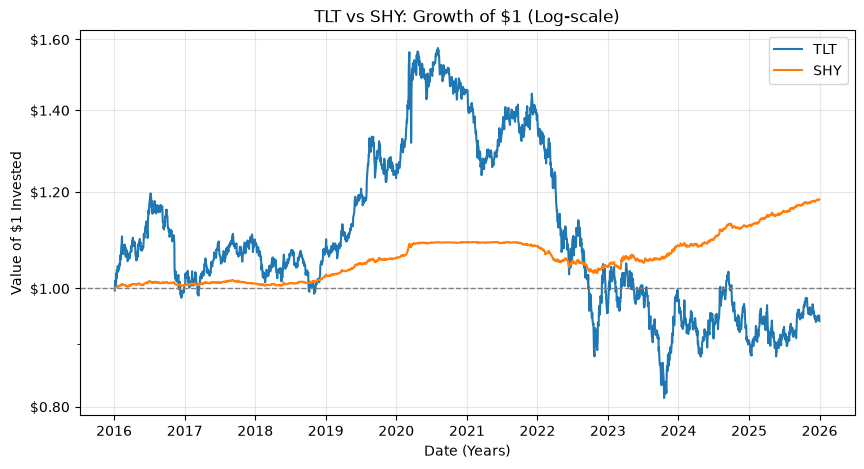

In [ ]:
from matplotlib.ticker import FuncFormatter, NullFormatter
growth = (1 + returns).cumprod()
fig, ax = plt.subplots(figsize=(10, 5))

# loop pattern to plot each asset
for ticker in TICKERS:
    ax.plot(growth.index, growth[ticker], label = ticker)
# Log scale, with dollar labels
ax.set_yscale("log")
ax.set_yticks([0.8, 1.0, 1.2, 1.4,1.6])
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:.2f}"))   # show them as $0.80, $1.00, ...
ax.yaxis.set_minor_formatter(NullFormatter()) 
# Format the Y-axis to show $0.80 instead of 1.0...
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.grid(True, which="major", alpha=0.3)
ax.set_title("TLT vs SHY: Growth of $1 (Log-scale)")
ax.set_xlabel("Date (Years)")
ax.set_ylabel("Value of $1 Invested")
ax.legend()
plt.show()


## Table
Side-by-side comparison of **annualized return, annualized volatility, and maximum drawdown**.

In [32]:
n_days = len(returns) # 2513 trading days in teh dataset

# Annualized return, is the constant yearly rate of return that would give the same cumulative return as the actual returns over the period.

ann_return = growth.iloc[-1] ** (252/ n_days) - 1

# Annualized volatility, is the standard deviation of daily returns. "how far a typical day moves from average"
ann_vol = returns.std() * np.sqrt(252)

# Maximum drawdown, is the maximum loss from a peak to a trough of a portfolio.
running_peak = growth.cummax() # highest value reached so far
drawdown = growth / running_peak - 1 # % below that peak
max_dd = drawdown.min() # Worst day.

table = pd.DataFrame({
    "Annualized Return": ann_return,
    "Annualized Volatility": ann_vol,
    "Maximum Drawdown": max_dd,
})
table.map("{:.2%}".format)

,Annualized Return,Annualized Volatility,Maximum Drawdown
TLT,-0.62%,14.99%,-48.35%
SHY,1.70%,1.56%,-5.71%


## Context
Find the **five best and five worst days** for each asset, then look up the news to see what caused them.

In [33]:
for ticker in TICKERS:
    print(f"{ticker}: 5 best days")
    print(returns[ticker].nlargest(5).map("{:.2%}".format))
    print(f"\n{ticker}: 5 worst days")
    print(returns[ticker].nsmallest(5).map("{:.2%}".format))
    print("\n" + "-" * 30 + "\n")

TLT: 5 best days
Date
2020-03-20    7.52%
2020-03-16    6.48%
2020-03-06    5.20%
2020-03-23    4.12%
2022-11-10    3.85%
Name: TLT, dtype: str

TLT: 5 worst days
Date
2020-03-17    -6.67%
2020-03-18    -5.64%
2020-03-10    -5.13%
2016-11-09    -4.24%
2020-03-11    -3.68%
Name: TLT, dtype: str

------------------------------

SHY: 5 best days
Date
2023-03-13    1.00%
2023-03-15    0.59%
2024-08-02    0.56%
2020-03-09    0.55%
2023-03-10    0.54%
Name: SHY, dtype: str

SHY: 5 worst days
Date
2022-06-13    -0.51%
2022-02-10    -0.51%
2020-03-10    -0.44%
2023-03-27    -0.42%
2022-06-10    -0.42%
Name: SHY, dtype: str

------------------------------



| Asset | Date | Return | What happened |
|---|---|---|---|
| TLT | 2020-03-20 | 7.52% | Long yields fell sharply as the Fed ramped up emergency Treasury buying during COVID market panic | Best |
| TLT | 2020-03-17 | -6.67% | 1 Trillion dollar Stimulus package induced fear of new bond supply| Worst |
| SHY | 2023-03-13  |  1.00% | First trading day after Silicon Valley Bank failed | Best 
| SHY | 2022-06-13  | -0.51% | A hot May CPI print (8.6%) | Worst
| | | | |

## The Paragraph
> **Which asset is actually riskier, and does taking on that extra risk result in a higher return?**

TLT is clearly riskier, with annualized volatility of 14.99% versus 1.56% for SHY, daily moves as large as 5 to 7% versus about 1%, and a maximum drawdown of 48.35% (from about $1.57 at the 2020 peak to $0.82 in late 2023) versus 5.71%. Most of that is duration risk: with a duration of roughly 17 years, TLT swings hard on any move in long-term yields, whether the cause is inflation (the 2022 hiking cycle), fiscal and supply fears (the day after the 2016 election and the March 2020 stimulus), or a liquidity crunch like March 2020, when 8 of its 10 most extreme days occurred. SHY mainly carries near-term Fed policy risk and some reinvestment risk; its worst days followed hot CPI prints and hawkish Fed signals in 2022, and its best came when the March 2023 SVB collapse led markets to price out hikes, but a 2-year duration keeps those moves small. TLT’s extra risk went unrewarded, returning -0.62% a year and ending below its starting $1, while SHY returned 1.70% a year and grew to about $1.18. Per unit of volatility, SHY earned 1.09 to TLT’s -0.04, so short-term Treasuries won this decade on both raw and risk-adjusted returns.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 1: returns and risk"
git push
```